In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

plt.style.use("ggplot")

In [ ]:
df = pd.read_csv("heart_disease_uci.csv")

df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [ ]:
print("Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

df.describe()

Shape: (920, 16)

Missing Values:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-n

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [ ]:
# Preprocessing
# Remove rows where target is missing
df = df[df['num'].notna()]

# Convert target into binary classification
df['num'] = (df['num'] > 0).astype(int)

# Keep only numerical columns
df = df.select_dtypes(include=['int64', 'float64'])

# Features and Target
X = df.drop("num", axis=1)
y = df["num"]

# Handle missing values
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(X)

print("Shape after preprocessing:", X.shape)

Shape after preprocessing: (920, 7)


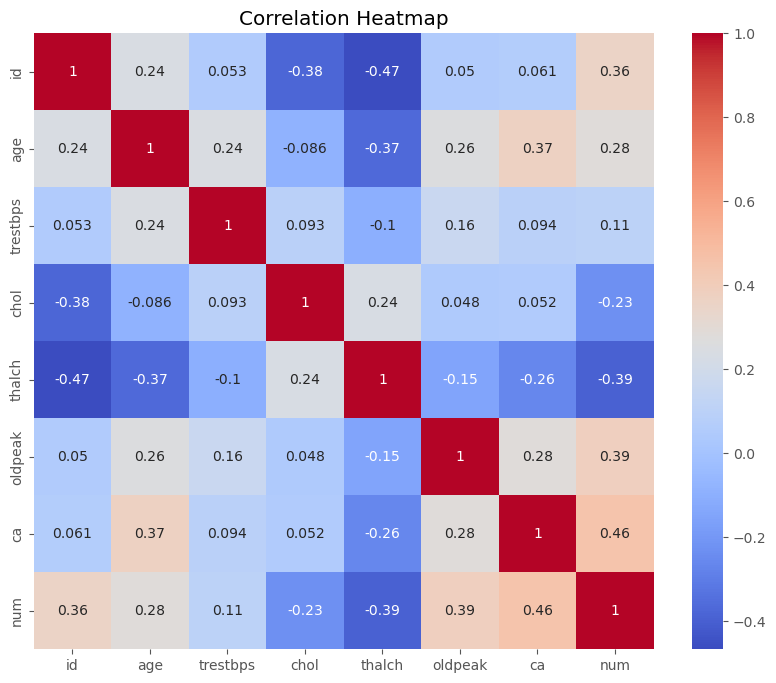

In [ ]:
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    cmap='coolwarm',
    annot=True
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Train-Test Split & Standardization
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 736
Testing samples: 184


In [ ]:
# Train Ridge Model
ridge = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=0.1,
    random_state=42
)

ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

ridge_accuracy = accuracy_score(y_test, ridge_pred)

print("Ridge Accuracy:", round(ridge_accuracy,4))

Ridge Accuracy: 0.7826


In [ ]:
# Train Lasso Model
lasso = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=0.05,
    random_state=42
)

lasso.fit(X_train, y_train)

lasso_pred = lasso.predict(X_test)

lasso_accuracy = accuracy_score(y_test, lasso_pred)

print("Lasso Accuracy:", round(lasso_accuracy,4))

Lasso Accuracy: 0.7772


In [ ]:
# Compare accuracy
results = pd.DataFrame({

    "Model":["Ridge","Lasso"],

    "Accuracy":[ridge_accuracy,
                lasso_accuracy]

})

results

,Model,Accuracy
0,Ridge,0.782609
1,Lasso,0.777174


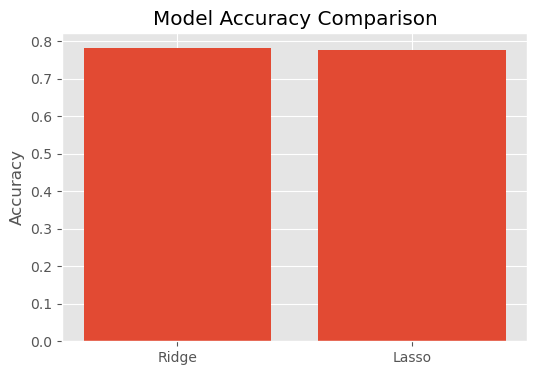

In [ ]:
plt.figure(figsize=(6,4))

plt.bar(results["Model"],
        results["Accuracy"])

plt.title("Model Accuracy Comparison")

plt.ylabel("Accuracy")

plt.show()

In [ ]:
print("Ridge Confusion Matrix")

print(confusion_matrix(y_test,ridge_pred))

print(classification_report(y_test,ridge_pred))

Ridge Confusion Matrix
[[58 17]
 [23 86]]
              precision    recall  f1-score   support

           0       0.72      0.77      0.74        75
           1       0.83      0.79      0.81       109

    accuracy                           0.78       184
   macro avg       0.78      0.78      0.78       184
weighted avg       0.79      0.78      0.78       184



In [ ]:
print("Lasso Confusion Matrix")

print(confusion_matrix(y_test,lasso_pred))

print(classification_report(y_test,lasso_pred))

Lasso Confusion Matrix
[[60 15]
 [26 83]]
              precision    recall  f1-score   support

           0       0.70      0.80      0.75        75
           1       0.85      0.76      0.80       109

    accuracy                           0.78       184
   macro avg       0.77      0.78      0.77       184
weighted avg       0.79      0.78      0.78       184



In [ ]:
# Coefficient Comparison
feature_names = df.drop("num", axis=1).columns

coef = pd.DataFrame({

    "Feature":feature_names,

    "Ridge":ridge.coef_[0],

    "Lasso":lasso.coef_[0]

})

coef.round(3)

coef

,Feature,Ridge,Lasso
0,id,0.458902,0.410299
1,age,0.038779,0.000000
2,trestbps,0.079599,0.000000
3,chol,-0.341108,-0.204092
4,thalch,-0.481716,-0.421016
5,oldpeak,0.835815,0.685023
6,ca,0.569184,0.420565


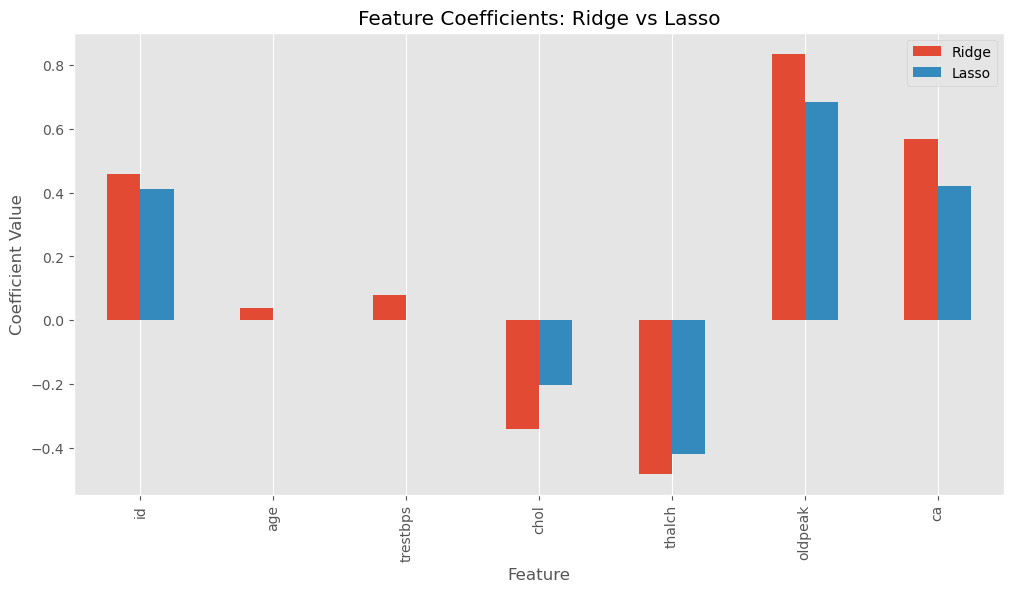

In [ ]:
# Coefficient Bar Chart
coef.set_index("Feature").plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Feature Coefficients: Ridge vs Lasso")

plt.ylabel("Coefficient Value")

plt.grid(axis="y")

plt.show()

In [ ]:
# Count Selected Features
ridge_features = np.sum(ridge.coef_[0] != 0)
lasso_features = np.sum(lasso.coef_[0] != 0)

print("Number of Features Used")

print("Ridge :", ridge_features)

print("Lasso :", lasso_features)

Number of Features Used
Ridge : 7
Lasso : 5
